# Omar — omar_rgb

Branch: feat/rgb-segmentation

BGR→RGB dönüşümüyle sabit renk aralığı; dört kontrol maskesi, alan yüzdesi, baş örtüşmesi, dört sınıf ve doğru/yanlış sayısı.

**Durum:** Ekibin ortak (Nesli'nin G1/G2'de seçip dondurduğu) RGB aralığı ve eşikleriyle K1–K4 çalıştırıldı. İlk çalıştırma Omar'ın kendi aralığıyla yapılmıştı; ekip tek ayar kullansın diye ortak ayara geçildi ve kontrol yeniden çalıştırıldı (`individual_notes/omar.md`). Sonuçlar `results/rgb_results.csv` içindedir. Altı görüntülük bir deneyle gerçek işyeri güvenilirliği iddia edilmez.

## 1. Ortam ve ortak veri


In [1]:
from pathlib import Path
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src" / "common.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Notebook'u klonlanan depo içinden açın.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.common import load_config, load_dataset
records = load_dataset()
print(f"Kaynak listesinde {len(records)} görüntü var.")
if not records:
    print("Veri henüz eklenmedi. Bu dosya deney başlangıç şablonudur.")

from src import rgb

settings = load_config("rgb_config.json")
print("Ayar durumu:", settings.get("status", "ortak proje ayarları"))


Kaynak listesinde 6 görüntü var.
Ayar durumu: configured


## 2. Deney öncesi tahmin

Kayıt: `docs/predictions.csv`, deney kimliği `rgb_baseline`. Tahmin ilk kontrol çalıştırmasından önce yazıldı ve sonra değiştirilmedi. Ortak ayara geçince kontrol yeniden çalıştırıldı; sonuçları zaten görmüş olduğum için yeni tahmin yazılmadı.

In [2]:
import pandas as pd
pred = pd.read_csv(ROOT / "docs" / "predictions.csv")
for _, row in pred[pred["experiment_id"] == "rgb_baseline"].iterrows():
    print(row["recorded_at"])
    print("1.", row["prediction_sentence_1"])
    print("2.", row["prediction_sentence_2"])

2026-11-02T19:05:44+03:00
1. I expect the RGB range to find the yellow helmets in K2 and K3 but to struggle with the small distant helmet and with the low light of the night image, because a fixed RGB range depends on brightness.
2. I expect K4 to be wrongly called helmet_on_head or to be borderline, because the mask sees the yellow helmet in the hand, and K1 to come out uncertain because no head box exists.


## 3. Uygulama

- `src/rgb.py`: `create_mask` BGR girdiyi açıkça RGB'ye çevirir ve `cv2.inRange` ile 0/255 maske üretir.
- Aralık, ekibin ortak ayarıdır (Nesli'nin yalnızca **G1/G2** üzerinde seçip dondurduğu): alt `[180, 140, 0]`, üst `[255, 255, 120]` (`configs/rgb_config.json`). Omar'ın ilk aralığı `[170, 150, 0]`–`[255, 255, 100]` bununla değiştirildi; geliştirme görüntülerinde ikisi de G1/G2'yi doğru ayırıyor.
- `src/classification.py`: baş kutusu yoksa `uncertain`; baş örtüşmesi ≥ %5 ise `helmet_on_head`; aksi halde görüntü maske alanı ≥ %2,5 ise `helmet_off_head`; aksi halde `no_helmet` (`configs/experiment.json`, Derviş ile ortak).
- Kontrol öncesi hem RGB ayarı hem karar kuralı `frozen=true` yapıldı.

In [3]:
import cv2
import numpy as np
from src.common import load_image, mask_percentages
from src.rgb import create_mask
from src.classification import classify_mask

rgb_cfg = load_config("rgb_config.json")
rule = load_config()["decision_rule"]
print("Geliştirme görüntüleri (aralığın seçildiği görüntüler):")
for rec in load_dataset("development"):
    mask = create_mask(load_image(rec["relative_path"]), rgb_cfg)
    area, overlap = mask_percentages(mask, rec["head_roi"])
    pred_cls = classify_mask(mask, rec["head_roi"], rule)
    print(f'{rec["image_id"]}: alan %{area:.2f}, baş örtüşmesi %{overlap:.2f}, sınıf {pred_cls}, gerçek {rec["ground_truth_class"]}')

Geliştirme görüntüleri (aralığın seçildiği görüntüler):
G1: alan %0.87, baş örtüşmesi %0.03, sınıf no_helmet, gerçek no_helmet
G2: alan %9.73, baş örtüşmesi %24.56, sınıf helmet_on_head, gerçek helmet_on_head


## 4. Ölçüm ve çıktı (kontrol görüntüleri, dondurulmuş ayarlar)

Aşağıdaki hücre maskeleri yeniden üretir ve kaydedilmiş `results/rgb_results.csv` ile aynı olduğunu doğrular. Dosyaya yazmaz.

In [4]:
assert rgb_cfg["frozen"] and rule["frozen"], "Kontrol öncesi ayarlar dondurulmalı."
saved = pd.read_csv(ROOT / "results" / "rgb_results.csv").set_index("image_id")
rows = []
masks = {}
for rec in load_dataset("control"):
    image = load_image(rec["relative_path"])
    mask = create_mask(image, rgb_cfg)
    area, overlap = mask_percentages(mask, rec["head_roi"])
    pred_cls = classify_mask(mask, rec["head_roi"], rule)
    masks[rec["image_id"]] = (image, mask, rec)
    assert abs(area - saved.loc[rec["image_id"], "mask_area_percent"]) < 0.01
    assert pred_cls == saved.loc[rec["image_id"], "predicted_class"]
    rows.append({
        "Görüntü": rec["image_id"], "Koşul": rec["condition"],
        "Doğru sınıf": rec["ground_truth_class"], "Kuralın sınıfı": pred_cls,
        "Maske alanı %": round(area, 2),
        "Baş örtüşmesi %": overlap if overlap == "N/A" else round(overlap, 2),
        "Doğru": pred_cls == rec["ground_truth_class"], "TP/FP/FN": "N/A",
    })
table = pd.DataFrame(rows)
display(table)
print(f'Doğru sınıf sayısı: {int(table["Doğru"].sum())} / {len(table)}')

,Görüntü,Koşul,Doğru sınıf,Kuralın sınıfı,Maske alanı %,Baş örtüşmesi %,Doğru,TP/FP/FN
0,K1,daylight_site_head_cropped,uncertain,uncertain,0.00,N/A,True,N/A
1,K2,low_light_night,helmet_on_head,no_helmet,0.08,1.33,False,N/A
2,K3,distant_small_heads,helmet_on_head,helmet_on_head,0.03,12.02,True,N/A
3,K4,bright_studio_helmet_held,helmet_off_head,helmet_off_head,3.42,3.66,True,N/A


Doğru sınıf sayısı: 3 / 4


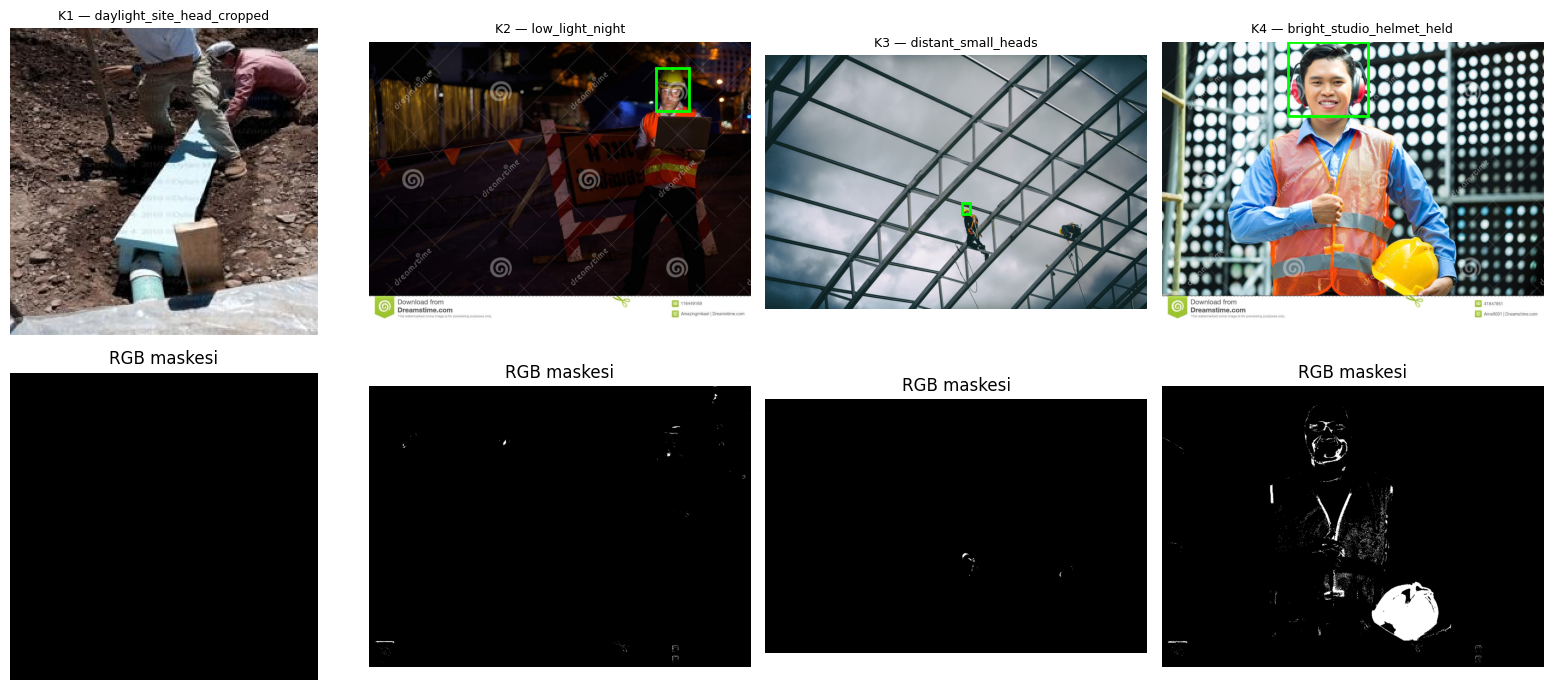

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for col, (image_id, (image, mask, rec)) in enumerate(masks.items()):
    axes[0, col].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    if rec["head_roi"]:
        x0, y0, x1, y1 = rec["head_roi"]
        axes[0, col].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="lime", linewidth=2))
    axes[0, col].set_title(f"{image_id} — {rec['condition']}", fontsize=9)
    axes[1, col].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title("RGB maskesi")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Hata analizi

**Kaçırma (kontrol sonucu): K2.** Gece görüntüsünde kural `no_helmet` dedi, gerçek sınıf `helmet_on_head`. Baret pikselleri yaklaşık RGB (92, 73, 9) ortancasına sahip; bunların yalnızca %2,1'i ortak aralıkta (R ≥ 180, G ≥ 140) olduğu için maske baretin neredeyse hiçbirini seçmedi. Sonraki kontrol: aynı K2'yi parlaklığa daha az duyarlı HSV ile ölçmek (Derviş'in deneyi); eşiği K2'ye bakarak değiştirmek yasak olduğundan RGB aralığı değiştirilmedi.

**Yanlış alarm (geliştirme örneği, test sonucu değil): G2.** Aşağıdaki hücre, G2 maskesinde seçilen piksellerin ne kadarının baş kutusunun dışında (yelek ve yansıtıcı şerit) kaldığını gösterir. Renk bölgesi bulundu ama baret nesnesi tanınmadı; bu yüzden tek başına maske alanı baret kanıtı değildir. Sonraki kontrol: baş kutusu dışındaki bileşenleri şekil ölçütüyle (en–boy oranı, doluluk) ayırıp aynı görüntüde yeniden ölçmek.

In [6]:
dev = {r["image_id"]: r for r in load_dataset("development")}
g2 = dev["G2"]
mask = create_mask(load_image(g2["relative_path"]), rgb_cfg)
x0, y0, x1, y1 = g2["head_roi"]
selected = int(np.count_nonzero(mask))
inside = int(np.count_nonzero(mask[y0:y1, x0:x1]))
print(f"G2: seçilen piksel {selected}, baş kutusu içinde {inside}, dışında %{100 * (selected - inside) / selected:.1f}")

G2: seçilen piksel 68009, baş kutusu içinde 12058, dışında %82.3


## 6. Sınırlılık ve doğrulama

- K3 doğru (örtüşme %12,02, eşik %5) ama maske alanı yalnızca %0,03 ve baret kutusu yaklaşık çizilmiştir (ortanca rengi sarı değildir).
- K4 doğru ama sınırda: baş örtüşmesi %3,66, eşik %5. Bu örtüşme elde tutulan baretten gelmiyor; baret kutusu baş kutusunun çok altındadır.
- Off-head eşiği (%2,5) G1/G2'den ayarlanamadı: yalnızca G1 (alan %0,87) onu sınırlar, G2'de önce örtüşme testi tetiklenir ve elde baret içeren geliştirme görüntüsü yoktur. Eşik ölçülmüş değil, varsayımdır.
- Altı görüntü, tek bir RGB aralığı: sonuçlar eğitim prototipi düzeyindedir.
- Kutu değerlendirmesi yapılmadı; TP/FP/FN `N/A`.
- Doğrulama: `scripts/validate_project.py` hatasız tamamlanır. Kişisel not: `individual_notes/omar.md`; yapay zekâ beyanı: `docs/ai_usage.md`.